# Supplementary Figure S3. Annotation agreement between tools

A–C restore the original comparison cohort and comparator-conditioned credit used by
Figure 2B–C: selected output plus classified discarded candidates reported by the
comparison tool. Six mismatched candidate archives retain selected output only. A is
non-canonical detection Jaccard, B is directional LW-class Cohen's kappa, and C is
per-family class agreement. D–E test FastRNA's ambiguity flag: pairs it labels ambiguous are far more often classified
inconsistently by the six other tools than unambiguous pairs of the same LW families.

In [1]:
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import Normalize

def _root() -> Path:
    here = Path.cwd().resolve()
    for base in [here, *here.parents]:
        if (base / "data").is_dir() and (base / "notebooks").is_dir():
            return base
    raise RuntimeError("run this from inside the analysis repo")

ROOT = _root()
data_file = lambda rel: ROOT / "data" / rel
_json = lambda rel: json.loads(data_file(rel).read_text())

import hashlib
import inspect
import pickle
from functools import lru_cache

REFRESH = False
CACHE_DIR = ROOT / ".cache" / "figS3"


def _input_key():
    h = hashlib.sha1()
    for path in sorted(data_file("comparison").rglob("*")):
        if path.is_file():
            st = path.stat()
            h.update(f"{path.relative_to(ROOT)}|{st.st_size}|{st.st_mtime_ns}".encode())
    return h.hexdigest()[:12]


INPUT_KEY = _input_key()


def disk_cache(fn):
    """Zero-argument fn computed once per input fingerprint and kept on disk."""
    try:
        src = inspect.getsource(fn)
    except (OSError, TypeError):
        src = fn.__code__.co_code.hex()
    path = CACHE_DIR / f"{fn.__name__}-{INPUT_KEY}-{hashlib.sha1(src.encode()).hexdigest()[:8]}.pkl"

    @lru_cache(maxsize=1)
    def wrapper():
        if path.exists() and not REFRESH:
            return pickle.loads(path.read_bytes())
        out = fn()
        CACHE_DIR.mkdir(parents=True, exist_ok=True)
        path.write_bytes(pickle.dumps(out))
        return out
    return wrapper


def save(fig, rel):
    path = ROOT / rel
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path)
    return path

plt.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 300, "savefig.bbox": "tight",
    "savefig.pad_inches": 0.08,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica Neue", "Helvetica", "DejaVu Sans"],
    "font.size": 8.5, "axes.labelsize": 9, "axes.titlesize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.linewidth": 0.8, "xtick.major.width": 0.8, "ytick.major.width": 0.8,
    "xtick.direction": "out", "ytick.direction": "out",
    "axes.grid": False, "legend.frameon": False,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
BLUE, ORANGE, GREEN, RED, GREY = "#4C72B0", "#DD8452", "#55A868", "#C44E52", "0.55"
POINT_FACE, POINT_EDGE, FIT = "#C9C9C9", "0.15", "#111111"

CUT = 80.0

LW = ["cWW", "tWW", "cWH", "tWH", "cWS", "tWS", "cHH", "tHH", "cHS", "tHS", "cSS", "tSS"]
TOOLS = ["parse", "fr3d", "rnaview", "barnaba", "rnapolis", "bpnet"]
TOOL_LABELS = ["FastRNA", "FR3D", "RNAView", "barnaba", "RNApolis", "BPNET"]

def finish(ax):
    """House chrome: all four spines, thin, outward ticks, no grid."""
    for side in ("top", "right", "bottom", "left"):
        ax.spines[side].set_visible(True)
        ax.spines[side].set_linewidth(0.8)
    ax.grid(False)
    ax.tick_params(direction="out", width=0.8, length=3.5)
    return ax

def letter(fig, ax, s, dx=-0.030, dy=0.012):
    box = ax.get_position()
    fig.text(box.x0 + dx, box.y1 + dy, s, fontsize=13, fontweight="bold",
             ha="left", va="bottom")

def pair_scores() -> pd.DataFrame:
    return pd.read_json(data_file("reference/scores/pair_scores_uniques_parse.jsonl"), lines=True)

def scored_pairs(lw_only=True) -> pd.DataFrame:
    """Unambiguous, scored per-pair records."""
    df = pair_scores()
    df = df[~df["is_ambiguous"].fillna(False) & df["score"].notna()].copy()
    return df[df["lw_class"].isin(LW)].copy() if lw_only else df

def _resolution(m):
    """Resolution for either method.

    The EM keys carry a non-ASCII Angstrom sign; looking for "(A)" instead drops
    every cryo-EM structure silently.
    """
    if not isinstance(m, dict):
        return None
    return (m.get("EM Diffraction Resolution (Å)") or m.get("Refinement_resolution")
            or m.get("EM Resolution (Å)"))

def structure_scores() -> pd.DataFrame:
    sc = _json("reference/scores/scores_all_uniques.json")["scores"]
    md = _json("reference/metadata/metadata_cache.json")
    vm, nt = md["validation_metrics"], md["nucleotide_counts"]
    rows = []
    for pdb, info in sc.items():
        m = vm.get(pdb) if isinstance(vm.get(pdb), dict) else {}
        rows.append({"pdb": pdb, "pairs_score": info.get("pairs_score"),
                     "backbone_suiteness": info.get("backbone_suiteness"),
                     "n_pairs": info.get("n_pairs", 0),
                     "n_residues_scored": info.get("n_residues_scored", 0),
                     "method": m.get("Experimental_method"),
                     "resolution": _resolution(m), "clashscore": m.get("clashscore"),
                     "rnasuiteness": m.get("rnasuiteness"),
                     "n_nucleotides": nt.get(pdb),
                     "deposited": m.get("Deposition_Date")})
    return pd.DataFrame(rows)

def runtime() -> pd.DataFrame:
    df = pd.read_csv(data_file("benchmark/dssr_PARSE_time_benchmark.csv"))
    df = df[(df["Nucleotides"] > 0) & (df["dssr_avg"] > 0) & (df["parse_avg"] > 0)].copy()
    df["ratio"] = df["dssr_avg"] / df["parse_avg"]
    return df

WEIGHTS = _json("reference/scoring_tables/penalty_weights.json")["penalty_weights"]
ISSUES = list(WEIGHTS)
ISSUE_LABELS = {"distance": "H-bond distance", "hbond_angles": "H-bond angles",
                "incorrect_hbond_count": "H-bond count", "stretch": "Stretch",
                "opening": "Opening", "stagger": "Stagger", "propeller": "Propeller",
                "shear": "Shear", "buckle": "Buckle", "clash": "Clash"}

def hist_grid(fig, spec, df, params, xlabel, cols=3):
    """A small-multiples grid of histograms inside one gridspec cell."""
    rows = int(np.ceil(len(params) / cols))
    sub = spec.subgridspec(rows, cols, wspace=0.42, hspace=0.62)
    axes = []
    for i, p in enumerate(params):
        ax = fig.add_subplot(sub[i // cols, i % cols])
        vals = pd.to_numeric(df[p], errors="coerce").dropna()
        if len(vals) > 20000:
            vals = vals.sample(20000, random_state=1)
        ax.hist(vals, bins=40, color=BLUE, alpha=0.8)
        ax.set_xlabel(p.replace("_", " "), fontsize=7.5)
        ax.tick_params(labelsize=6.5)
        if i % cols == 0:
            ax.set_ylabel("Count", fontsize=7.5)
        finish(ax)
        axes.append(ax)
    return axes


## Shared tool-comparison helpers
Same pair loaders and matrix definitions as main Figure 2B-C, so the bars there and the heatmaps here are computed identically.

In [2]:
from functools import lru_cache
from itertools import combinations
from matplotlib.colors import Normalize


def _heatmap(ax, matrix, label, vmin, vmax, fig=None, cax=None):
    """Full tool-by-tool (or tool-by-class) matrix with the value in every cell, 6 pt
    without the leading zero (".85") so two decimals fit a cell at print size."""
    cmap = plt.cm.Blues.copy()
    cmap.set_bad("0.90")
    im = ax.imshow(matrix.to_numpy(float), cmap=cmap, norm=Normalize(vmin, vmax))
    ax.set_xticks(range(len(matrix.columns)), matrix.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(matrix.index)), matrix.index)
    finish(ax)
    ax.tick_params(length=0)
    hi = vmin + 0.62 * (vmax - vmin)
    for r in range(matrix.shape[0]):
        for c in range(matrix.shape[1]):
            v = matrix.iat[r, c]
            if np.isnan(v):
                ax.text(c, r, "n/a", ha="center", va="center", fontsize=6, color="0.40")
            else:
                ax.text(c, r, "1" if v >= 0.995 else f"{v:.2f}"[1:], ha="center",
                        va="center", fontsize=6, color="white" if v > hi else "0.15")
    if cax is not None:
        p = cax.get_position()
        horizontal = p.width * (fig or ax.figure).get_size_inches()[0] > \
            p.height * (fig or ax.figure).get_size_inches()[1]
        cb = (fig or ax.figure).colorbar(im, cax=cax,
                                         orientation="horizontal" if horizontal else "vertical")
        if horizontal:
            cax.xaxis.set_ticks_position("top")
            cax.xaxis.set_label_position("top")
    else:
        cb = (fig or ax.figure).colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cb.set_label(label)
    cb.outline.set_visible(False)
    return im

MATRIX_TOOLS = ["parse", "dssr", "fr3d", "rnaview", "barnaba", "rnapolis", "bpnet"]
MATRIX_LABELS = ["FastRNA", "DSSR", "FR3D", "RNAView", "barnaba", "RNApolis", "BPNET"]
JSON_PAIR_FILES = {
    "parse": "comparison/parse_pairs.json",
    "dssr": "comparison/dssr_pairs.json",
    "rnaview": "comparison/rnaview_pairs.json",
    "barnaba": "comparison/barnaba_pairs.json",
    "rnapolis": "comparison/rnapolis_pairs.json",
    "bpnet": "comparison/bpnet_pairs.json",
}
_NUM = __import__("re").compile(r"^(-?\d+)([A-Za-z]?)$")
UNCLASSIFIED = "?"


def _residue(chain, number, icode=""):
    m = _NUM.match(str(number))
    if not chain or m is None:
        raise ValueError(f"uncanonicalizable residue id: {chain!r} {number!r}")
    appended = m.group(2)
    if appended and icode:
        raise ValueError(f"two insertion codes: {chain!r} {number!r} {icode!r}")
    return (str(chain), int(m.group(1)), icode or appended)


def _flip(lw):
    if lw == UNCLASSIFIED:
        return lw
    if lw.startswith("n"):
        return "n" + _flip(lw[1:])
    if len(lw) != 3:
        return lw
    return lw[0] + lw[2] + lw[1]


def _flip_label(label):
    return "|".join(_flip(part) for part in label.split("|"))


def _pair_entry(res1, res2, label):
    if res2 < res1:
        return (res2, res1), _flip_label(label)
    return (res1, res2), label


def _adjacent(res1, res2):
    """Sequence neighbours: same chain, residue numbers one apart. FastRNA never
    reports these (they are excluded at candidate generation), so they are dropped
    from every tool; otherwise each one counts against FastRNA as a missed pair."""
    return res1[0] == res2[0] and abs(res1[1] - res2[1]) == 1


def _ingest(rows):
    pairs = {}
    for res1, res2, label in rows:
        if _adjacent(res1, res2):
            continue
        key, canonical_label = _pair_entry(res1, res2, label)
        pairs.setdefault(key, set()).add(canonical_label)
    return pairs


def _load_json_pairs(tool):
    raw = _json(JSON_PAIR_FILES[tool])
    out = {}
    for pdb, record in raw.items():
        if record.get("status") != "ok":
            continue
        rows = []
        for row in record["pairs"]:
            c1, n1, c2, n2, lw = row[:5]
            rows.append((_residue(c1, n1), _residue(c2, n2), lw or UNCLASSIFIED))
        out[pdb] = _ingest(rows)
    return out


def _hub_unit(unit):
    fields = unit.split("|")
    if len(fields) < 5 or fields[1] != "1":
        return None
    icode = fields[7] if len(fields) >= 8 else ""
    return _residue(fields[2], fields[4], icode)


def _load_fr3d_pairs():
    out = {}
    for csv_path in sorted(data_file("comparison/fr3d").glob("[0-9A-Z]*.csv")):
        rows = []
        for line in csv_path.read_text(errors="replace").splitlines():
            if not line.strip():
                continue
            fields = [part.strip().strip('"') for part in line.split('\",\"')]
            if len(fields) != 3:
                continue
            res1, res2 = _hub_unit(fields[0]), _hub_unit(fields[2])
            if res1 is not None and res2 is not None:
                rows.append((res1, res2, fields[1]))
        out[csv_path.stem] = _ingest(rows)
    return out


@lru_cache(maxsize=1)
def _load_all_pairsets():
    pairsets = {tool: _load_json_pairs(tool) for tool in JSON_PAIR_FILES}
    pairsets["fr3d"] = _load_fr3d_pairs()
    return pairsets


def _single_family(labels):
    if any("|" in lw for lw in labels):
        return None
    fams = {lw for lw in labels if len(lw) == 3 and lw[0] in "ct"
            and lw[1] in "WHS" and lw[2] in "WHS"}
    return next(iter(fams)) if len(fams) == 1 else None


def _single_family_units(pairsets_by_pdb):
    units = {}
    for pdb, pairsets in pairsets_by_pdb.items():
        for key, labels in pairsets.items():
            fam = _single_family(labels)
            if fam is not None:
                units[(pdb, key)] = fam
    return units



def _canon_lw(lw):
    """LW class in canonical face order (W < H < S), so tHW and tWH are one class."""
    order = {"W": 0, "H": 1, "S": 2}
    return lw[0] + lw[2] + lw[1] if order[lw[1]] > order[lw[2]] else lw


WATSON_CRICK = {frozenset("GC"), frozenset("AU")}


@lru_cache(maxsize=1)
def _residue_names():
    return _json("comparison/residue_names.json")


def _is_canonical(pdb, key, labels):
    names = _residue_names().get(pdb, {})
    bases = [names.get(f"{chain}|{num}|{icode}") for chain, num, icode in key]
    if None in bases or frozenset(bases) not in WATSON_CRICK:
        return False
    return any(part == "cWW" for lw in labels for part in lw.split("|"))


@lru_cache(maxsize=1)
def _parse_candidates():
    raw = _json("comparison/parse_candidates.json")
    return {pdb: _ingest([(_residue(c1, n1), _residue(c2, n2), lw or UNCLASSIFIED)
                          for c1, n1, c2, n2, lw, _ in rec["pairs"]])
            for pdb, rec in raw.items() if pdb != "_meta"}


@lru_cache(maxsize=None)
def fastrna_credited(partner):
    """{pdb: {pair: labels}}: FastRNA's output plus candidates `partner` confirms."""
    pairsets, candidates = _load_all_pairsets(), _parse_candidates()
    out = {}
    for pdb, ours in pairsets["parse"].items():
        theirs = pairsets[partner].get(pdb, {})
        extra = {k: v for k, v in candidates.get(pdb, {}).items()
                 if k in theirs and k not in ours and UNCLASSIFIED not in v}
        out[pdb] = {**ours, **extra}
    return out


def _pair_lists(a, b):
    """The two pair lists compared for tools a and b (FastRNA credited against b)."""
    pairsets = _load_all_pairsets()
    pa = fastrna_credited(b) if a == "parse" else pairsets[a]
    pb = fastrna_credited(a) if b == "parse" else pairsets[b]
    return pa, pb


def _empty_matrix():
    return pd.DataFrame(np.eye(len(MATRIX_LABELS)), index=MATRIX_LABELS, columns=MATRIX_LABELS)


@disk_cache
def noncanonical_detection_matrix():
    """Jaccard on non-canonical pairs for every tool pair (ambiguous labels left out,
    as in main Figure 2B)."""
    pairsets = _load_all_pairsets()
    mat = _empty_matrix()
    for (a, la), (b, lb) in combinations(zip(MATRIX_TOOLS, MATRIX_LABELS), 2):
        inter = union = 0
        list_a, list_b = _pair_lists(a, b)
        for pdb in list_a.keys() & list_b.keys():
            pa, pb = list_a[pdb], list_b[pdb]
            for key in pa.keys() | pb.keys():
                labels = pa.get(key, set()) | pb.get(key, set())
                if any("|" in lw for lw in labels) or _is_canonical(pdb, key, labels):
                    continue
                union += 1
                inter += key in pa and key in pb
        mat.loc[la, lb] = mat.loc[lb, la] = inter / union
    return mat


@disk_cache
def noncanonical_kappa_matrix():
    """Cohen's kappa on the LW class of non-canonical pairs both tools detect, each
    with one unambiguous class. Chance agreement here is only 12-15%, so kappa is
    well behaved (on canonical pairs, nearly all cWW, it is not)."""
    pairsets = _load_all_pairsets()
    units = {tool: _single_family_units(pairsets[tool]) for tool in MATRIX_TOOLS}
    mat = _empty_matrix()
    for (a, la), (b, lb) in combinations(zip(MATRIX_TOOLS, MATRIX_LABELS), 2):
        n = agree = 0
        c1, c2 = Counter(), Counter()
        list_a, list_b = _pair_lists(a, b)
        ua = units[a] if a != "parse" else _single_family_units(list_a)
        ub = units[b] if b != "parse" else _single_family_units(list_b)
        for (pdb, key), x in ua.items():
            y = ub.get((pdb, key))
            if y is None or _is_canonical(pdb, key, {x, y}):
                continue
            n += 1
            agree += x == y
            c1[x] += 1
            c2[y] += 1
        po, pe = agree / n, sum(c1[k] * c2[k] for k in c1) / n ** 2
        mat.loc[la, lb] = mat.loc[lb, la] = (po - pe) / (1 - pe)
    return mat


## Panel A
Non-canonical base-pair detection agreement between every pair of tools (Jaccard)

          FastRNA   DSSR   FR3D  RNAView  barnaba  RNApolis  BPNET
FastRNA     1.000  0.861  0.629    0.604    0.633     0.577  0.670
DSSR        0.861  1.000  0.541    0.599    0.634     0.545  0.587
FR3D        0.629  0.541  1.000    0.426    0.420     0.544  0.692
RNAView     0.604  0.599  0.426    1.000    0.518     0.470  0.449
barnaba     0.633  0.634  0.420    0.518    1.000     0.465  0.467
RNApolis    0.577  0.545  0.544    0.470    0.465     1.000  0.604
BPNET       0.670  0.587  0.692    0.449    0.467     0.604  1.000


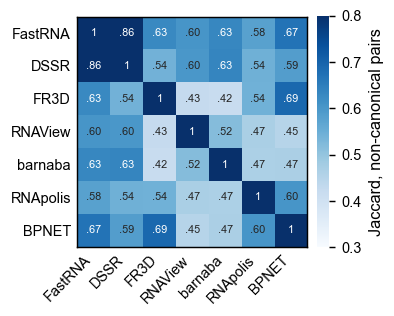

In [3]:
print(noncanonical_detection_matrix().round(3))


def draw_b(ax, fig=None, cax=None):
    _heatmap(ax, noncanonical_detection_matrix(), "Jaccard, non-canonical pairs", 0.3, 0.8, fig, cax)


fig, ax = plt.subplots(figsize=(3.0, 2.6))
draw_b(ax, fig)
fig.tight_layout()
save(fig, "figures/supplemental/figS3_A_noncanonical_detection.png")
plt.show()


## Panel B
Cohen's kappa on the LW class of non-canonical pairs both tools detect, every pair of tools

          FastRNA   DSSR   FR3D  RNAView  barnaba  RNApolis  BPNET
FastRNA     1.000  0.949  0.972    0.897    0.759     0.854  0.954
DSSR        0.949  1.000  0.917    0.890    0.743     0.854  0.939
FR3D        0.972  0.917  1.000    0.935    0.762     0.792  0.966
RNAView     0.897  0.890  0.935    1.000    0.709     0.826  0.951
barnaba     0.759  0.743  0.762    0.709    1.000     0.725  0.777
RNApolis    0.854  0.854  0.792    0.826    0.725     1.000  0.832
BPNET       0.954  0.939  0.966    0.951    0.777     0.832  1.000


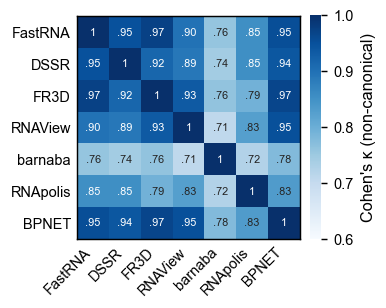

In [4]:
print(noncanonical_kappa_matrix().round(3))


def draw_c(ax, fig=None, cax=None):
    _heatmap(ax, noncanonical_kappa_matrix(), "Cohen's \u03ba (non-canonical)", 0.6, 1.0, fig, cax)


fig, ax = plt.subplots(figsize=(3.0, 2.6))
draw_c(ax, fig)
fig.tight_layout()
save(fig, "figures/supplemental/figS3_B_noncanonical_kappa.png")
plt.show()


## Panel C
LW-class agreement with FastRNA, per class and tool

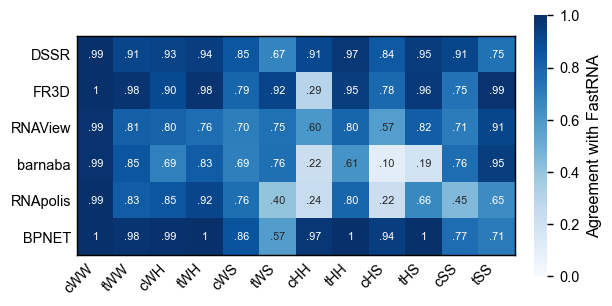

In [5]:
@disk_cache
def class_agreement_with_fastrna():
    pairsets = _load_all_pairsets()
    units = {tool: {k: _canon_lw(v) for k, v in _single_family_units(pairsets[tool]).items()}
             for tool in MATRIX_TOOLS}
    rows = {}
    for tool, label in zip(MATRIX_TOOLS[1:], MATRIX_LABELS[1:]):
        ours = {k: _canon_lw(v) for k, v in _single_family_units(fastrna_credited(tool)).items()}
        theirs = units[tool]
        both, either = Counter(), Counter()
        for key in ours.keys() & theirs.keys():
            a, b = ours[key], theirs[key]
            either[a] += 1
            if a == b:
                both[a] += 1
            else:
                either[b] += 1
        rows[label] = {lw: both[lw] / either[lw] if either[lw] else np.nan for lw in LW}
        print(f"{label:9s} smallest class: {min(either[lw] for lw in LW):,} pairs")
    return pd.DataFrame(rows).T


def draw_d(ax, fig=None, cax=None):
    _heatmap(ax, class_agreement_with_fastrna(), "Agreement with FastRNA", 0.0, 1.0, fig, cax)

fig, ax = plt.subplots(figsize=(4.8, 2.5))
draw_d(ax, fig)
fig.tight_layout()
save(fig, "figures/supplemental/figS3_C_class_agreement.png")
plt.show()


## Panels D and E
FastRNA's ambiguous pairs are the pairs the other tools disagree on: overall (D) and by ambiguity type (E)

3,589 ambiguous and 738,810 unambiguous FastRNA pairs in 1,176 structures


,flagged (%),confident (%),bootstrap p,P (cluster-robust),significance
comparison,,,,,
all ambiguous vs family-matched,56.163900,23.592935,< 0.0005,6.197721e-265,***
cHH|cWW,44.138756,24.679352,< 0.0005,8.889326e-25,***
tHH|tWW,67.975207,25.261290,< 0.0005,8.609141e-77,***
cHH|cWH,73.989899,31.944888,< 0.0005,4.325497e-70,***
tHH|tWH,55.425220,28.986896,< 0.0005,1.727230e-22,***
cWH|cWW,44.674556,8.063423,< 0.0005,1.677120e-44,***
tWH|tWW,53.061224,13.617863,< 0.0005,9.417320e-47,***


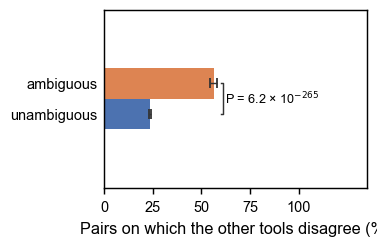

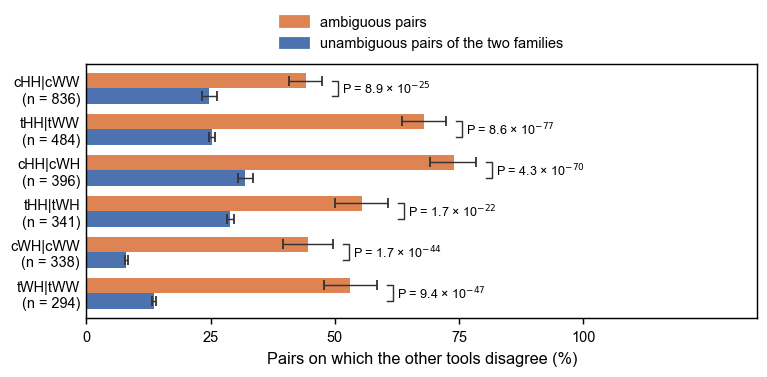

In [6]:
from collections import Counter
canon = _canon_lw
OTHER = ["dssr", "fr3d", "rnaview", "barnaba", "rnapolis", "bpnet"]

def family(labels):
    fams = {canon(lw) for lw in labels if len(lw) == 3 and lw[0] in "ct"
            and lw[1] in "WHS" and lw[2] in "WHS"}
    return next(iter(fams)) if len(fams) == 1 else None

@disk_cache
def votes_table():
    pairsets = _load_all_pairsets()
    rows = []
    for pdb, pairs in pairsets["parse"].items():
        for key, labels in pairs.items():
            amb = [lw for lw in labels if "|" in lw]
            own = None if amb else family(labels)
            if not amb and own is None:
                continue
            opts = tuple(sorted({canon(x) for x in amb[0].split("|")})) if amb else None
            votes = {t: f for t in OTHER
                     if (lab := pairsets[t].get(pdb, {}).get(key)) is not None
                     and (f := family(lab)) is not None}
            rows.append((pdb, bool(amb), own, opts, votes))
    return pd.DataFrame(rows, columns=["pdb", "amb", "own", "opts", "votes"])


V = votes_table().copy()
V["k"] = V.votes.map(len)
V["split"] = V.votes.map(lambda v: len(set(v.values())) > 1)
print(f"{V.amb.sum():,} ambiguous and {(~V.amb).sum():,} unambiguous FastRNA pairs in "
      f"{V.pdb.nunique():,} structures")

E = V[V.k >= 2].reset_index(drop=True)

B_REPS = 2000
pdb_idx, pdbs = pd.factorize(E.pdb)
nP = len(pdbs)

def counts(mask):
    """Per-structure (disputed, total) for the pairs selected by mask."""
    m = np.asarray(mask)
    return (np.bincount(pdb_idx[m], weights=E.split.to_numpy()[m].astype(float), minlength=nP),
            np.bincount(pdb_idx[m], minlength=nP).astype(float))

UN_FAM = {f: counts((~E.amb) & (E.own == f)) for f in E.loc[~E.amb, "own"].unique()}
AMB_TYPES = [o for o, _ in Counter(E[E.amb].opts).most_common(6)]
AMB_T = {o: counts(E.amb & (E.opts == o)) for o in AMB_TYPES}
ALL_AMB, ALL_UN = counts(E.amb), counts(~E.amb)
W_ALL = Counter()
for o in E[E.amb].opts:
    for f in o:
        W_ALL[f] += 1 / len(o)

def matched(w, weights):
    r = {f: (w @ UN_FAM[f][0]) / (w @ UN_FAM[f][1]) for f in weights if f in UN_FAM}
    return sum(r[f] * weights[f] for f in r) / sum(weights[f] for f in r)

def stats(w):
    out = {"all_amb": (w @ ALL_AMB[0]) / (w @ ALL_AMB[1]), "all_un": (w @ ALL_UN[0]) / (w @ ALL_UN[1]),
           "all_matched": matched(w, W_ALL)}
    for o in AMB_TYPES:
        out[("amb", o)] = (w @ AMB_T[o][0]) / (w @ AMB_T[o][1])
        out[("mat", o)] = matched(w, {f: 0.5 for f in o})
    return out

POINT2 = stats(np.ones(nP))
rng = np.random.default_rng(7)
BS = pd.DataFrame([stats(np.bincount(rng.integers(0, nP, nP), minlength=nP).astype(float))
                   for _ in range(B_REPS)])

def ci(k):
    return BS[k].quantile(0.025), BS[k].quantile(0.975)

def pval(a, b):
    d = BS[a] - BS[b]
    p = 2 * min((d <= 0).mean(), (d >= 0).mean())
    return max(p, 1 / B_REPS)

def stars(p):
    return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "n.s."

from scipy.stats import norm

def cluster_p(weights, amb_counts):
    """Two-sided test of flagged rate minus family-matched rate, with a cluster-robust
    (sandwich / delta-method) variance over structures. Uses the same per-structure counts
    (disputed, total) as the bootstrap; weights = each family's share of the baseline."""
    fams = [f for f in weights if f in UN_FAM]
    wsum = sum(weights[f] for f in fams)
    d_a, n_a = amb_counts
    r_a = d_a.sum() / n_a.sum()
    diff = r_a
    u = (d_a - r_a * n_a) / n_a.sum()
    for f in fams:
        d_f, n_f = UN_FAM[f]
        r_f = d_f.sum() / n_f.sum()
        wf = weights[f] / wsum
        diff -= wf * r_f
        u -= wf * (d_f - r_f * n_f) / n_f.sum()
    G = len(u)
    se = np.sqrt(G / (G - 1) * (u ** 2).sum())
    return 2 * norm.sf(abs(diff / se))

def p_text(p):
    if p < 1e-300:
        return "P < 10$^{-300}$"
    m, e = f"{p:.1e}".split("e")
    return f"P = {p:.2g}" if p >= 1e-3 else f"P = {m} × 10$^{{{int(e)}}}$"

rows = [{"comparison": "all ambiguous vs family-matched", "flagged (%)": 100 * POINT2["all_amb"],
         "confident (%)": 100 * POINT2["all_matched"], "p": pval("all_amb", "all_matched"),
         "P (cluster-robust)": cluster_p(dict(W_ALL), ALL_AMB)}]
for o in AMB_TYPES:
    rows.append({"comparison": "|".join(o), "flagged (%)": 100 * POINT2[("amb", o)],
                 "confident (%)": 100 * POINT2[("mat", o)], "p": pval(("amb", o), ("mat", o)),
                 "P (cluster-robust)": cluster_p({f: 0.5 for f in o}, AMB_T[o])})
SIG = pd.DataFrame(rows).set_index("comparison")
SIG["significance"] = SIG["P (cluster-robust)"].map(stars)
SIG["p"] = SIG.p.map(lambda p: f"< {1 / B_REPS:.4f}" if p <= 1 / B_REPS else f"{p:.4f}")
SIG = SIG.rename(columns={"p": "bootstrap p"})

def p_label(p):
    """Exact P value, as m x 10^e for small values."""
    if p >= 1e-3:
        return f"P = {p:.2g}"
    m, e = f"{p:.1e}".split("e")
    return f"P = {m} \u00d7 10$^{{{int(e)}}}$"



def _hbar(ax, y, key, colour, h):
    v = 100 * POINT2[key]; lo, hi = (100 * c for c in ci(key))
    ax.barh(y, v, h, color=colour)
    ax.errorbar(v, y, xerr=[[v - lo], [hi - v]], fmt="none", ecolor="0.2", capsize=2.5, lw=0.8)
    return hi


def _vbracket(ax, y1, y2, x, text):
    ax.plot([x, x + 1.2, x + 1.2, x], [y1, y1, y2, y2], color="0.2", lw=0.8)
    ax.text(x + 2.0, (y1 + y2) / 2, text, ha="left", va="center", fontsize=7)


def draw_e(ax):
    """D: all ambiguous pairs vs unambiguous pairs of the same families."""
    h = 0.38
    xa = _hbar(ax, h / 2, "all_amb", ORANGE, h)
    xm = _hbar(ax, -h / 2, "all_matched", BLUE, h)
    _vbracket(ax, -h / 2, h / 2, max(xa, xm) + 2,
              p_label(SIG.loc["all ambiguous vs family-matched", "P (cluster-robust)"]))
    ax.set_yticks([-h / 2, h / 2], ["unambiguous", "ambiguous"])
    ax.set_ylim(-1.1, 1.1)
    ax.set_xlim(0, 135)
    ax.set_xticks([0, 25, 50, 75, 100])
    ax.set_xlabel("Pairs on which the other tools disagree (%)")
    finish(ax)
    ax.tick_params(axis="y", length=0)


def draw_f(ax):
    """E: the same comparison for each of the six commonest ambiguity types."""
    h = 0.38
    ys = np.arange(len(AMB_TYPES))[::-1]
    for y, o in zip(ys, AMB_TYPES):
        xa = _hbar(ax, y + h / 2, ("amb", o), ORANGE, h)
        xm = _hbar(ax, y - h / 2, ("mat", o), BLUE, h)
        _vbracket(ax, y - h / 2, y + h / 2, max(xa, xm) + 2, p_label(SIG.loc["|".join(o), "P (cluster-robust)"]))
    ax.set_yticks(ys, [f"{'|'.join(o)}\n(n = {int(AMB_T[o][1].sum())})" for o in AMB_TYPES])
    ax.set_ylim(ys.min() - 0.6, ys.max() + 0.6)
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=ORANGE), plt.Rectangle((0, 0), 1, 1, color=BLUE)],
              labels=["ambiguous pairs", "unambiguous pairs of the two families"], loc="lower center",
              bbox_to_anchor=(0.5, 1.0), ncol=1)
    ax.set_xlim(0, 135)
    ax.set_xticks([0, 25, 50, 75, 100])
    ax.set_xlabel("Pairs on which the other tools disagree (%)")
    finish(ax)
    ax.tick_params(axis="y", length=0)


display(SIG)
fig, ax = plt.subplots(figsize=(3.0, 2.0))
draw_e(ax)
fig.tight_layout()
save(fig, "figures/supplemental/figS3_D_ambiguous_disagreement.png")
plt.show()

fig, ax = plt.subplots(figsize=(6.0, 3.0))
draw_f(ax)
fig.tight_layout()
save(fig, "figures/supplemental/figS3_E_ambiguous_by_type.png")
plt.show()


## Source data for A-B

In [7]:
import sys
import importlib
sys.path.insert(0, str(ROOT / "scripts" / "validation"))
import figure2_comparison as _comparison
_comparison = importlib.reload(_comparison)

SOURCE_DATA = ROOT / "figures" / "source_data"
SOURCE_DATA.mkdir(parents=True, exist_ok=True)
noncanonical_detection_matrix().to_csv(SOURCE_DATA / "figS3_detection_matrix.csv")
noncanonical_kappa_matrix().to_csv(SOURCE_DATA / "figS3_classification_kappa.csv")


@disk_cache
def candidate_credit_detection():
    comparison = _comparison.Comparison(ROOT / "data")
    credit_rows = []
    for tool, label in zip(MATRIX_TOOLS[1:], MATRIX_LABELS[1:]):
        for stage in ("selected", "credited"):
            pdbs, shared, union, excluded = comparison.detection_counts("parse", tool, stage)
            for k, kind in enumerate(("canonical", "non-canonical")):
                intersection, denominator = shared[:, k].sum(), union[:, k].sum()
                credit_rows.append({"tool": label, "stage": stage, "kind": kind,
                                    "structures": len(pdbs), "intersection": int(intersection),
                                    "union": int(denominator), "jaccard": intersection / denominator})
    return pd.DataFrame(credit_rows)


candidate_credit_detection().to_csv(SOURCE_DATA / "figS3_candidate_credit_detection.csv", index=False)

## Combined figure


row gap 0.83 in


text scaled x1.08: 7 pt prints at 7.0 pt at page width


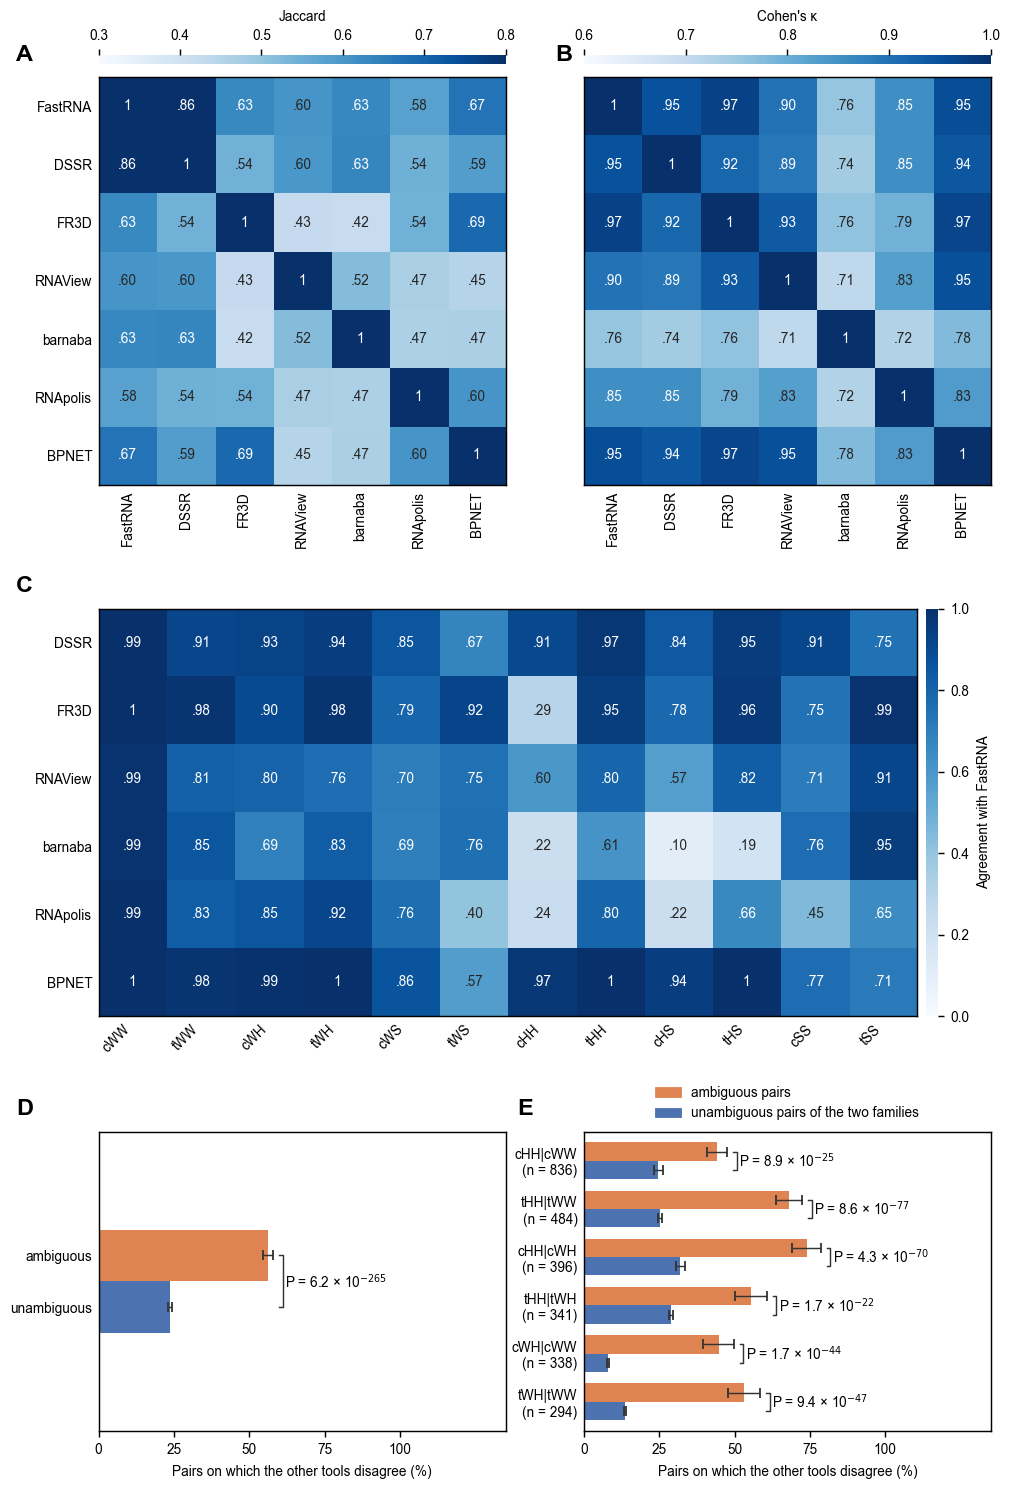

In [8]:
plt.rcParams.update({"xtick.labelsize": 7, "ytick.labelsize": 7, "axes.labelsize": 8,
                     "legend.fontsize": 7})
PANEL_IN, CBAR_W, CBAR_PAD = 1.615, 0.09, 0.07
FIG_W = 7.5
TOP = tuple(0.62 + k * (PANEL_IN + 1.05) for k in range(3))
FIG_H = TOP[2] + PANEL_IN + 0.50
fig = plt.figure(figsize=(FIG_W, FIG_H))
inch = lambda x, y, w, h: [x / FIG_W, 1 - (y + h) / FIG_H, w / FIG_W, h / FIG_H]
square = lambda x, row, w=PANEL_IN: fig.add_axes(inch(x, TOP[row], w, PANEL_IN))
cbar = lambda ax: fig.add_axes([ax.get_position().x1 + CBAR_PAD / FIG_W, ax.get_position().y0,
                                CBAR_W / FIG_W, ax.get_position().height])

D_W = PANEL_IN * 12 / 6
ax_b, ax_c = square(0.6, 0), square(2.9, 0)
ax_d, ax_e = square(0.6, 1, D_W), square(5.0, 1)
ax_f = square(0.9, 2, 4.4)
cbar_top = lambda ax: fig.add_axes([ax.get_position().x0, ax.get_position().y1 + 0.10 / FIG_H,
                                    ax.get_position().width, 0.07 / FIG_H])
cax_b, cax_c, cax_d = cbar_top(ax_b), cbar_top(ax_c), cbar(ax_d)

draw_b(ax_b, fig, cax_b)
draw_c(ax_c, fig, cax_c)
ax_c.tick_params(labelleft=False)
draw_d(ax_d, fig, cax_d)
cax_b.set_xlabel("Jaccard")
cax_c.set_xlabel("Cohen's κ")
cax_c.set_xticks([0.6, 0.7, 0.8, 0.9, 1.0], ["0.6", "0.7", "0.8", "0.9", "1.0"])
for ax in (ax_b, ax_c):
    ax.tick_params(axis="x", labelrotation=90)
    for t in ax.get_xticklabels():
        t.set_ha("center")
draw_e(ax_e)
draw_f(ax_f)
ax_e.set_box_aspect(None)


MARGIN_L, MARGIN_R = 0.012, 0.988
inv = fig.transFigure.inverted()


def extent(group):
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    boxes = [a.get_tightbbox(r).transformed(inv) for a in group]
    return min(b.x0 for b in boxes), max(b.x1 for b in boxes)


def shift(group, dx):
    for a in group:
        q = a.get_position()
        a.set_position([q.x0 + dx, q.y0, q.width, q.height])


def spread(row):
    spans = [extent(g) for g in row]
    widths = [x1 - x0 for x0, x1 in spans]
    gap = (MARGIN_R - MARGIN_L - sum(widths)) / max(len(row) - 1, 1)
    assert gap * FIG_W > 0.06, f"row does not fit the page: gap {gap * FIG_W:.2f} in"
    print(f"row gap {gap * FIG_W:.2f} in")
    x = MARGIN_L
    for g, (x0, _), w in zip(row, spans, widths):
        shift(g, x - x0)
        x += w + gap


x0, _ = extent([ax_b, cax_b])
shift([ax_b, cax_b], MARGIN_L - x0)
spread([[ax_d, cax_d], [ax_e]])
x0, _ = extent([ax_f])
shift([ax_f], MARGIN_L - x0)

GH_GAP = 0.60
f_right = MARGIN_R * FIG_W
g_labels = (ax_b.get_position().x0 - extent([ax_b, cax_b])[0]) * FIG_W
side = (f_right - MARGIN_L * FIG_W - g_labels - GH_GAP) / 2
grow = side - PANEL_IN
top_gh = 1 - ax_b.get_position().y1
for ax, cax, x in ((ax_b, cax_b, MARGIN_L * FIG_W + g_labels),
                   (ax_c, cax_c, f_right - side)):
    ax.set_position(inch(x, top_gh * FIG_H, side, side))
    q = ax.get_position()
    cax.set_position([q.x0, q.y1 + 0.10 / FIG_H, q.width, 0.07 / FIG_H])
for a in (ax_d, cax_d, ax_e, ax_f):
    q = a.get_position()
    a.set_position([q.x0, q.y0 - grow / FIG_H, q.width, q.height])

fig.canvas.draw()
pa, pb = ax_b.get_position(), ax_c.get_position()
pc = ax_d.get_position()
ax_d.set_aspect("auto")
ax_d.set_position([pa.x0, pc.y1 - pa.height, pb.x1 - pa.x0, pa.height])


def fit_c_to_b():
    """Narrow C until its colour bar, label included, ends where B's frame ends."""
    for _ in range(5):
        q = ax_d.get_position()
        cax_d.set_position([q.x1 + CBAR_PAD / FIG_W, q.y0, CBAR_W / FIG_W, q.height])
        fig.canvas.draw()
        to_fig = fig.transFigure.inverted()
        over = (cax_d.get_tightbbox(fig.canvas.get_renderer()).transformed(to_fig).x1
                - ax_c.get_position().x1)
        if abs(over) * FIG_W < 0.002:
            break
        ax_d.set_position([q.x0, q.y0, q.width - over, q.height])


fit_c_to_b()
ROW3_H = 2.3 / FIG_H
y3 = ax_f.get_position().y1 - ROW3_H
ax_e.set_position([pa.x0, y3, pa.x1 - pa.x0, ROW3_H])
ax_f.set_position([pb.x0, y3, pb.x1 - pb.x0, ROW3_H])

fig.canvas.draw()
renderer = fig.canvas.get_renderer()
col_left = min(a.get_tightbbox(renderer).transformed(inv).x0 for a in (ax_b, ax_d, ax_e))
for ax, s in [(ax_b, "A"), (ax_c, "B"), (ax_d, "C"), (ax_e, "D"), (ax_f, "E")]:
    if ax in (ax_b, ax_d, ax_e):
        x = col_left
    elif ax is ax_c:
        x = ax.get_position().x0 - 0.22 / FIG_W
    else:
        x = ax.get_tightbbox(renderer).transformed(inv).x0
    fig.text(x, ax.get_position().y1 + 0.012, s, fontsize=12, fontweight="bold",
             ha="left", va="bottom")
TEXT_PT, LETTER_PT = 7, 12


def set_uniform_text(fig, size=TEXT_PT):
    import matplotlib.text as mtext
    for t in fig.findobj(mtext.Text):
        if t.get_fontsize() >= LETTER_PT and t.get_fontweight() in ("bold", 700):
            continue
        t.set_fontsize(size)


set_uniform_text(fig)

ROW_GAP_IN = 0.25


def restack_rows(fig, rows, gap_in=ROW_GAP_IN, margin_in=0.05, extras=()):
    """rows: list of lists of axes, top to bottom. extras: (axes, row index) pairs that
    move with a row but do not set its height (e.g. a panel spanning several rows).
    Panel letters (figure texts) and figure-level arrows move with the row they label."""
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    W, H = fig.get_size_inches()
    ft = lambda y_px: H - y_px / fig.dpi
    tops = [min(ft(a.get_tightbbox(r).y1) for a in row) for row in rows]
    bots = [max(ft(a.get_tightbbox(r).y0) for a in row) for row in rows]

    def row_of(y_ft):
        below = [i for i in range(len(rows)) if y_ft <= bots[i]]
        return min(below, key=lambda i: abs(tops[i] - y_ft)) if below else len(rows) - 1

    texts = [(t, row_of(ft(t.get_window_extent(r).y0))) for t in fig.texts]
    for t, i in texts:
        e = t.get_window_extent(r)
        tops[i], bots[i] = min(tops[i], ft(e.y1)), max(bots[i], ft(e.y0))
    deltas, cursor = [], margin_in
    for top, bot in zip(tops, bots):
        deltas.append(cursor - top)
        cursor += bot - top + gap_in
    H2 = cursor - gap_in + margin_in
    for a, i in extras:
        H2 = max(H2, H - a.get_position(original=True).y0 * H + deltas[i] + margin_in)
    fig.set_size_inches(W, H2)
    conv = lambda y_frac, d: (H2 - (H - y_frac * H + d)) / H2

    def move(a, d):
        p = a.get_position(original=True)
        a.set_position([p.x0, conv(p.y0, d), p.width, p.height * H / H2], which="both")

    for i, row in enumerate(rows):
        for a in row:
            move(a, deltas[i])
    for a, i in extras:
        move(a, deltas[i])
    for t, i in texts:
        x, y = t.get_position()
        t.set_position((x, conv(y, deltas[i])))
    for art in fig.artists:
        if hasattr(art, "_posA_posB") and art._posA_posB:
            (xa, ya), (xb, yb) = art._posA_posB
            d = deltas[row_of(H - ya * H)]
            art.set_positions((xa, conv(ya, d)), (xb, conv(yb, d)))

restack_rows(fig, [[ax_b, cax_b, ax_c, cax_c], [ax_d, cax_d], [ax_e, ax_f]])
import matplotlib.text as _mtext
def _print_scale(fig, page_in=7.2, pad=0.08):
    fig.canvas.draw()
    bb = fig.get_tightbbox(fig.canvas.get_renderer())
    return max(1.0, (bb.width + 2 * pad) / page_in)
fig.canvas.draw()
_texts = [t for t in fig.findobj(_mtext.Text) if t.get_text().strip()]
_base = {t: t.get_fontsize() for t in _texts}
_s = 1.0
for _ in range(6):
    _need = _print_scale(fig)
    if _s >= _need - 1e-3:
        break
    _s = _need * 1.01
    for _t in _texts:
        _t.set_fontsize(_base[_t] * _s)
print(f"text scaled x{_s:.2f}: 7 pt prints at {7 * _s * 7.2 / (_print_scale(fig) * 7.2):.1f} pt "
      f"at page width")
fit_c_to_b()
save(fig, "figures/supplemental/figS3.png")
plt.show()